# Exploración y Análisis Descriptivo del Dataset Insurance



JAIRO ANDRES MENDOZA PARADA



NRC-1395-Machine Learning



Semana 2







2 de Noviembre


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

Pandas permite la manipulación y análisis eficiente de datos tabulares (DataFrames).

Matplotlib es la librería fundamental para la creación de gráficos y visualización de distribuciones.

In [ ]:
df = pd.read_csv('/content/EIARV021_A2_V2_Anexo2.csv')

Carga del dataset

In [ ]:
df.head(22)

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
5,31,female,25.7,0,no,southeast,3756.62
6,46,female,33.4,1,no,southeast,8240.59
7,37,female,27.7,3,no,northwest,7281.51
8,37,male,29.8,2,no,northeast,6406.41
9,60,female,25.8,0,no,northwest,28923.14


Inspección inicial de los primeros registros

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Información general sobre estructura, tipos de datos y valores no nulos

In [ ]:
df.describe(include='all')

,age,sex,bmi,children,smoker,region,expenses
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.665471,1.094918,NaN,NaN,13270.422414
std,14.049960,NaN,6.098382,1.205493,NaN,NaN,12110.011240
min,18.000000,NaN,16.000000,0.000000,NaN,NaN,1121.870000
25%,27.000000,NaN,26.300000,0.000000,NaN,NaN,4740.287500
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.030000
75%,51.000000,NaN,34.700000,2.000000,NaN,NaN,16639.915000


Resumen estadístico descriptivo (incluyendo categóricas)

Analisis:

Se inspeccionó la estructura del DataFrame Insurance (1338 registros y 7 columnas), identificando los tipos de datos de cada variable (numéricas: age, bmi, children, expenses; y categóricas: sex, smoker, region), y se analizó la integridad de los datos verificando el conteo de valores no nulos.

El reporte de df.info() confirma que todas las columnas cuentan con 1338 valores no nulos, lo que demuestra categóricamente que el dataset no tiene valores faltantes (missing values). Esto agiliza la fase de limpieza al no requerir imputaciones ni eliminaciones de filas por nulos. En el resumen estadístico inicial se observa, por ejemplo, que la edad promedio (age) es de ~39.2 años, el índice de masa corporal (bmi) promedio es de ~30.66 y los gastos médicos (expenses) presentan una media de ~13,270.42 con una alta dispersión (desviación estándar de ~12,110), evidenciando asimetría o valores atípicos elevados.


In [ ]:
duplicados = df.duplicated().sum()

Verificación de filas duplicadas en el DataFrame

In [ ]:
duplicados = df.duplicated().sum()
print(f"Cantidad de filas duplicadas: {duplicados}")

if duplicados > 0:
    df = df.drop_duplicates()
    print("eliminado de filas duplicadas.")


print(f"Total de filas  en el dataset limpio: {df.shape[0]}")

Cantidad de filas duplicadas: 0
Total de filas  en el dataset limpio: 1337


Cuántos duplicados hay antes de borrarlos

Si el número de duplicados es mayor a 0, se eliminan para garantizar la limpieza.

Cuántas filas quedaron en total para estar seguros

In [ ]:
print(df[['age', 'bmi', 'children', 'expenses']].describe())

               age          bmi     children      expenses
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.665520     1.095737  13279.121638
std      14.044333     6.100664     1.205571  12110.359657
min      18.000000    16.000000     0.000000   1121.870000
25%      27.000000    26.300000     0.000000   4746.340000
50%      39.000000    30.400000     1.000000   9386.160000
75%      51.000000    34.700000     2.000000  16657.720000
max      64.000000    53.100000     5.000000  63770.430000


Medidas numéricas detalladas (incluyendo mediana que corresponde al percentil 50)

In [ ]:
for col in ['sex', 'smoker', 'region']:
    print(f"\nVariable: {col}")
    print(df[col].value_counts())
    print(f"Moda: {df[col].mode()[0]}")


Variable: sex
sex
male      675
female    662
Name: count, dtype: int64
Moda: male

Variable: smoker
smoker
no     1063
yes     274
Name: count, dtype: int64
Moda: no

Variable: region
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
Moda: southeast


Análisis de frecuencias y modas para variables categóricas.


Analisis:

percentil: Es un valor que divide el conjunto de datos ordenados en partes porcentuales.

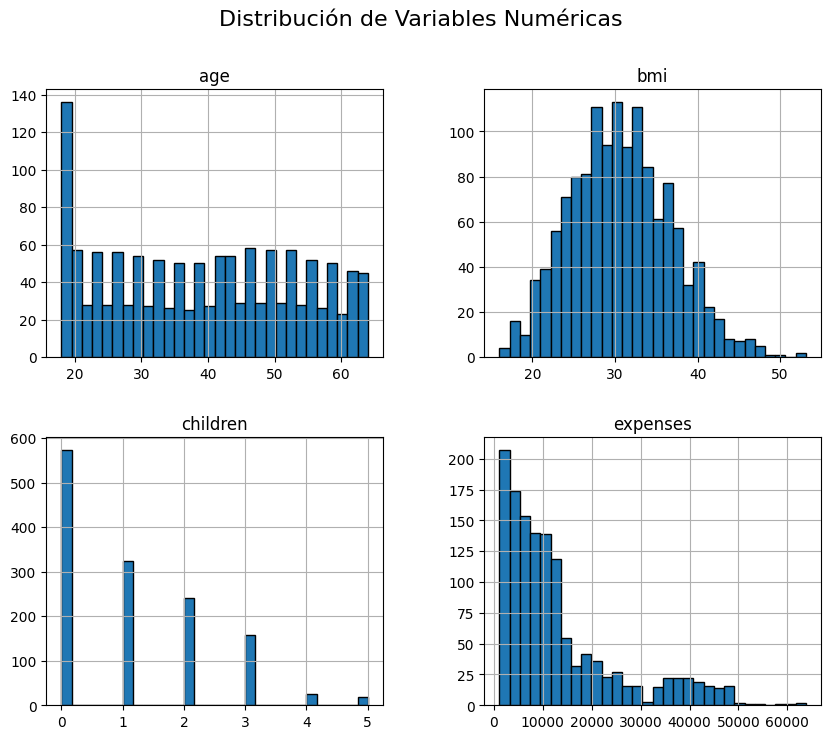

In [ ]:
df[['age', 'bmi', 'children', 'expenses']].hist(bins=30, figsize=(10, 8), edgecolor='black')
plt.suptitle('Distribución de Variables Numéricas', fontsize=16)
plt.show()

Histogramas para variables numéricas


La edad (age) tiene una distribución bastante estable con un pico muy marcado de clientes jóvenes de 18 y 19 años; el índice de masa corporal (bmi) se distribuye en una campana simétrica perfecta centrada cerca de 30, reflejando un peso moderado generalizado; la cantidad de hijos (children) disminuye rápidamente desde una gran mayoría de clientes sin hijos (cero) hasta un máximo de cinco; y los gastos médicos (expenses) presentan un fuerte sesgo a la derecha, donde la gran mayoría de asegurados pagan costos bajos o moderados al inicio, mientras una minoría de casos extremos eleva los costos hasta los 60,000.

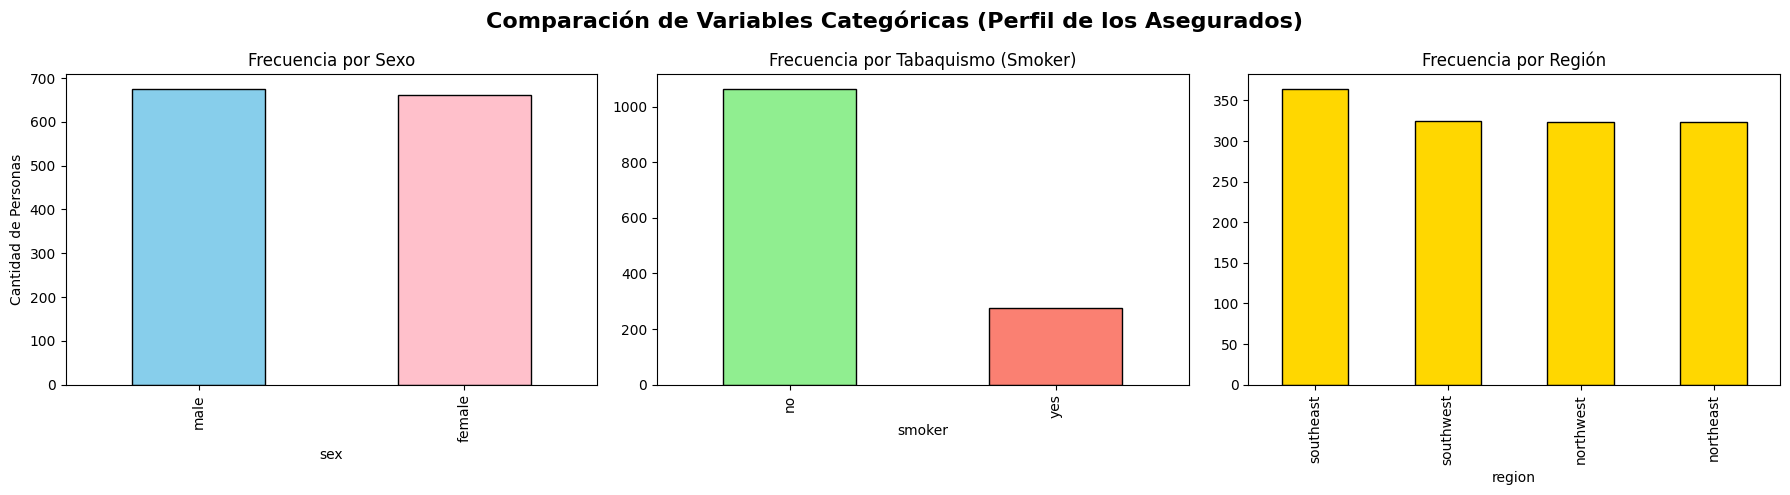

In [ ]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


fig.suptitle('Comparación de Variables Categóricas (Perfil de los Asegurados)', fontsize=16, fontweight='bold')


df['sex'].value_counts().plot(kind='bar', ax=axes[0], color=['skyblue', 'pink'], edgecolor='black')
axes[0].set_title('Frecuencia por Sexo')
axes[0].set_ylabel('Cantidad de Personas')

df['smoker'].value_counts().plot(kind='bar', ax=axes[1], color=['lightgreen', 'salmon'], edgecolor='black')
axes[1].set_title('Frecuencia por Tabaquismo (Smoker)')


df['region'].value_counts().plot(kind='bar', ax=axes[2], color='gold', edgecolor='black')
axes[2].set_title('Frecuencia por Región')

plt.tight_layout()
plt.show()

Diagramas de barras para variables categóricas

Analisis:

Se generaron histogramas para las variables numéricas (age, bmi, children, expenses) y diagramas de barras para las variables categóricas (sex, smoker, region), permitiendo evaluar gráficamente sus formas, asimetrías y frecuencias relativas.



El análisis exploratorio de los datos de seguros muestra que las variables de género y región están muy bien equilibradas y sin sesgos, aunque destaca un grupo inusualmente alto de jóvenes de 18 y 19 años. Por su parte, el índice de masa corporal (BMI) se comporta de forma muy ordenada y simétrica en forma de campana centrada en un promedio de 30.66, lo que indica que la mayoría de los asegurados manejan un peso corporal moderado.

El hallazgo más importante se encuentra en los gastos médicos (expenses), los cuales presentan un fuerte sesgo hacia la derecha: la gran mayoría de las personas gastan poco o moderadamente (con una mediana de (dinero) 9,386.16), pero existen unos pocos casos extremos que elevan los costos hasta los (dinero)  63770.43, arrastrando la media a $ 13,279.12. Al cruzar esto con el tabaquismo, se descubre que aunque los no fumadores son la mayoría abrumadora, el grupo minoritario de fumadores es el responsable directo de disparar estas reclamaciones financieras tan elevadas.





In [ ]:
import numpy as np

Importamos NumPy porque es la librería estándar para hacer cálculos matemáticos masivos y rápidos en toda una columna de golpe.











In [ ]:
df['expenses_log'] = np.log(df['expenses'])

Aplicamos el logaritmo natural a toda la columna 'expenses' de forma inmediata
(NumPy evita tener que recorrer los 1,337 registros uno por uno con ciclos lentos).

In [ ]:
print(df[['expenses', 'expenses_log']].head())

   expenses  expenses_log
0  16884.92      9.734176
1   1725.55      7.453301
2   4449.46      8.400538
3  21984.47      9.998092
4   3866.86      8.260198


Verificamos que se creó bien mostrando los primeros registros.


Los gastos originales (como (dinero)16,884 o (dinero)1,725) se convirtieron en números mucho más pequeños y controlables (como 9.73 y 7.45). Eso es justo el logaritmo en acción; comprime los números gigantes y acerca los valores para que la Inteligencia Artificial no se confunda con los extremos.

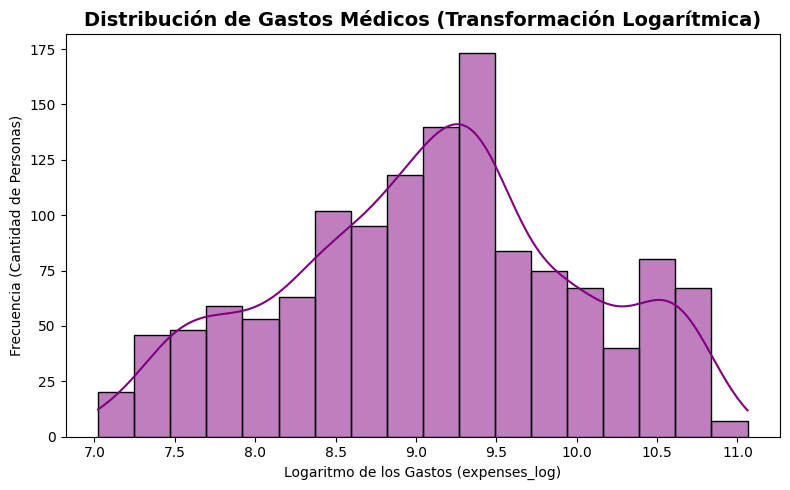

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['expenses_log'], kde=True, color='purple', edgecolor='black')


plt.title('Distribución de Gastos Médicos (Transformación Logarítmica)', fontsize=14, fontweight='bold')
plt.xlabel('Logaritmo de los Gastos (expenses_log)')
plt.ylabel('Frecuencia (Cantidad de Personas)')

plt.tight_layout()
plt.show()

Creamos el histograma con la columna transformada.

-Cola larga- de valores extremos desaparece y los datos toman una forma de campana mucho más limpia. Esto es lo que la  Inteligencia Artificial necesita para no alucinar.

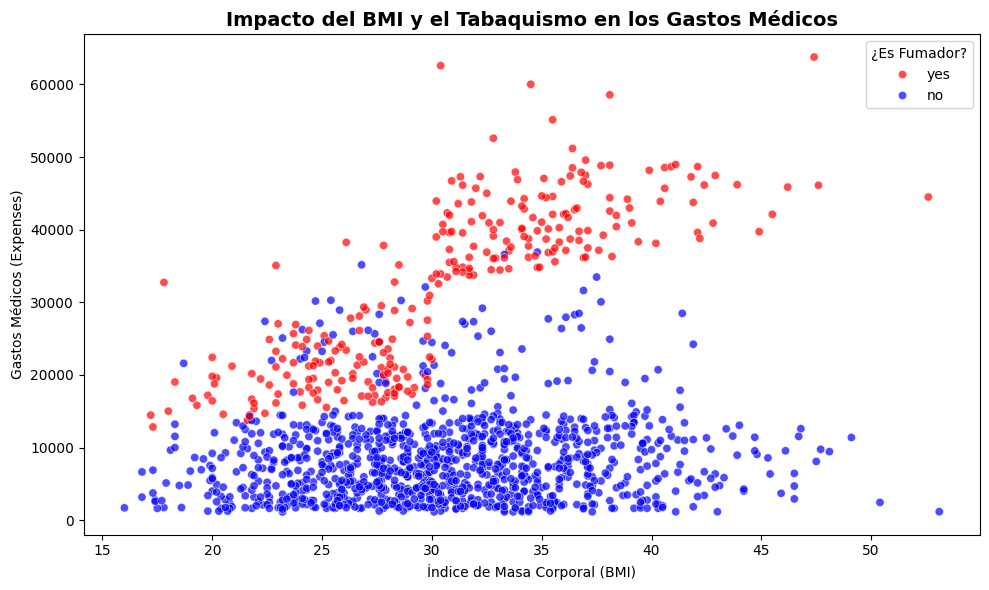

In [ ]:

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='bmi',
    y='expenses',
    hue='smoker',
    data=df,
    palette={'yes': 'red', 'no': 'blue'},
    alpha=0.7
)


plt.title('Impacto del BMI y el Tabaquismo en los Gastos Médicos', fontsize=14, fontweight='bold')
plt.xlabel('Índice de Masa Corporal (BMI)')
plt.ylabel('Gastos Médicos (Expenses)')
plt.legend(title='¿Es Fumador?')

plt.tight_layout()
plt.show()

Gráfico para cruzar BMI, Expenses y Tabaquismo.

No fumadores:sin importar si tienen un BMI bajo o alto, sus gastos se mantien de forma muy ordenada y bajita en la parte inferior de la gráfica.

Fumadores:si el fumador tiene un BMI alto (mayor a 30), sus gastos alcanzan los valores máximos extremos (los de $63,000).
El precio del seguro no sube por casualidad. Los puntos azules (no fumadores) siempre pagan poco sin importar su peso. Pero los puntos rojos (fumadores) explotan en costos, especialmente cuando se combinan con un índice de masa corporal (BMI) superior a 30.

Referencias



* Boschetti, A., & Massaron, L. (2018). *Python data science essentials: A practitioner's guide covering essential data science principles, tools, and techniques* (3.ª ed.). Packt Publishing. https://www.packtpub.com/product/python-data-science-essentials-third-edition/9781789537864



* Rothman, D. (2018). *Artificial intelligence by example: Develop machine intelligence from scratch using real artificial intelligence use cases* (1.ª ed.). Packt Publishing. https://www.packtpub.com/product/artificial-intelligence-by-example/9781788990547